## Modelo de generacion de caracteres 
### Universidad nacional Guillermo Brown
#### **Estudiantes:** Thiago Montenegro Yerumini, Brian Fernandez, Leonardo Carbajal.

In [16]:
# Empezamos cargando las liberias necesarias para el codigo
import numpy as np
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import seaborn as sns


from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

Creamos una funcion de carga para los distintos datos

In [17]:
def cargar_datos(nombre_archivo="the_festival.txt", autor="H. P. Lovecraft"):
    ruta_archivo = Path(f"Data/{nombre_archivo}")
    
    if not ruta_archivo.exists():
        print(f"El archivo {ruta_archivo} no existe.")
        return None, None
        
    try:
        with open(ruta_archivo, 'r', encoding='utf-8') as f:
            contenido = f.read()
            
        parrafos = [p.strip() for p in contenido.split('\n\n') if p.strip()]
        
        datos = []
        for i, parrafo in enumerate(parrafos):
            datos.append({
                'id_parrafo': i + 1,
                'texto': parrafo,
                'autor': autor,
                'origen': ruta_archivo.name
            })
            
        return pd.DataFrame(datos), contenido
        
    except Exception as e:
        print(f"Error leyendo {nombre_archivo}: {e}")
        return None, None

# Llamamos a la función indicando el autor
df_datos, texto = cargar_datos(nombre_archivo="the_festival.txt", autor="H. P. Lovecraft")

if texto is not None and not df_datos.empty:
    total_chars = len(texto)
    vocabulary = sorted(list(set(texto)))
    vocab_size = len(vocabulary)

    print(f"Archivo cargado: {df_datos['origen'].iloc[0]}")
    print(f"Autor asignado: {df_datos['autor'].iloc[0]}")
    print(f"Cantidad total de párrafos: {len(df_datos)}")
    print(f"Cantidad total de caracteres: {total_chars:,}")
    print(f"Tamaño del vocabulario de caracteres únicos: {vocab_size}")
else:
    print("No se pudo cargar el archivo o está vacío.")

Archivo cargado: the_festival.txt
Autor asignado: H. P. Lovecraft
Cantidad total de párrafos: 29
Cantidad total de caracteres: 20,365
Tamaño del vocabulario de caracteres únicos: 67


Análisis exploratorio, baseline, partición de
datos y métrica de evaluación

C:\Users\miguelybrian\AppData\Local\Temp\ipykernel_12780\1681192625.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(palabras_vals), y=list(palabras_keys), ax=axes[0, 0], palette="Blues_r")
C:\Users\miguelybrian\AppData\Local\Temp\ipykernel_12780\1681192625.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(chars_vals), y=list(chars_keys), ax=axes[0, 1], palette="Greens_r")


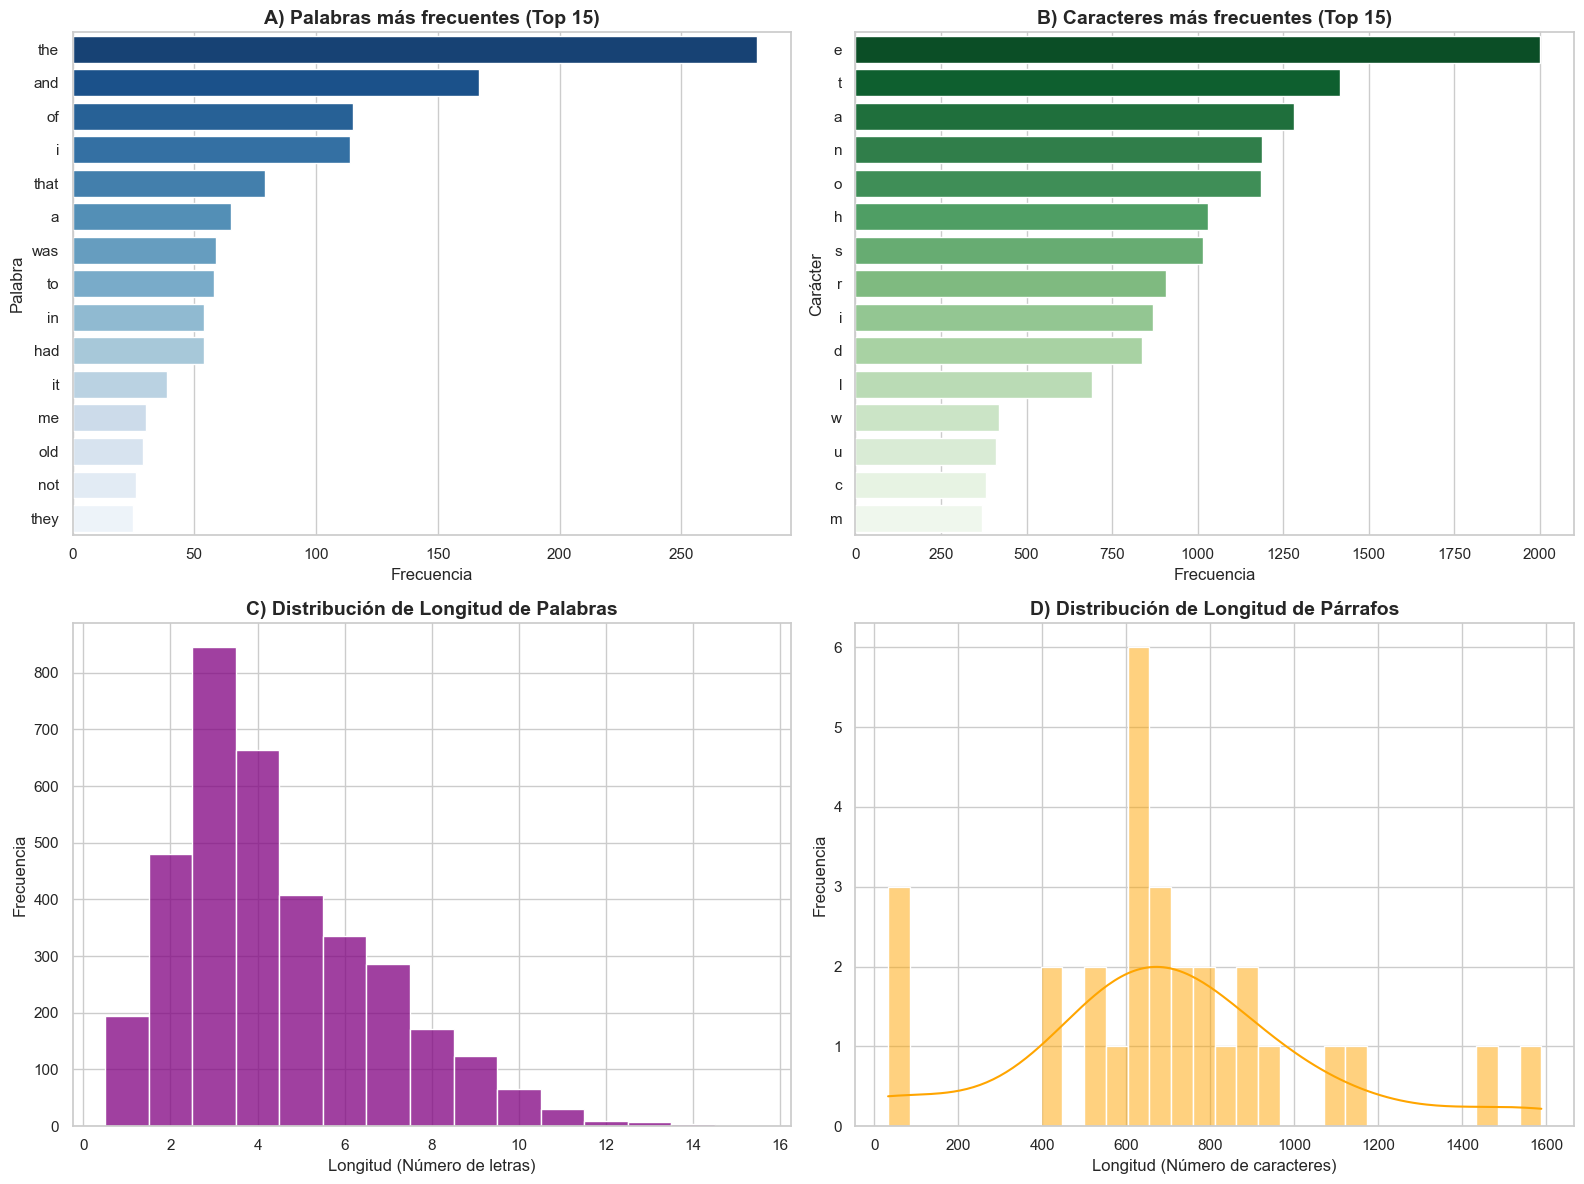

In [18]:
texto_completo = " ".join(df_datos['texto'])

palabras = re.findall(r'\b\w+\b', texto_completo.lower())
parrafos = df_datos['texto'].tolist()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
sns.set_theme(style="whitegrid")

# Palabras más frecuentes (Top 15)
top_palabras = Counter(palabras).most_common(15)
palabras_keys, palabras_vals = zip(*top_palabras) if top_palabras else ([], [])
sns.barplot(x=list(palabras_vals), y=list(palabras_keys), ax=axes[0, 0], palette="Blues_r")
axes[0, 0].set_title("A) Palabras más frecuentes (Top 15)", fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel("Frecuencia")
axes[0, 0].set_ylabel("Palabra")

#  Caracteres más frecuentes
caracteres = [c for c in texto_completo if c.strip()] 
top_chars = Counter(caracteres).most_common(15)
chars_keys, chars_vals = zip(*top_chars) if top_chars else ([], [])
sns.barplot(x=list(chars_vals), y=list(chars_keys), ax=axes[0, 1], palette="Greens_r")
axes[0, 1].set_title("B) Caracteres más frecuentes (Top 15)", fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel("Frecuencia")
axes[0, 1].set_ylabel("Carácter")

#  Distribución de Longitud de Palabras 
longitudes_palabras = [len(p) for p in palabras]
sns.histplot(longitudes_palabras, bins=range(1, max(longitudes_palabras) + 2) if longitudes_palabras else 10, 
             ax=axes[1, 0], color="purple", discrete=True)
axes[1, 0].set_title("C) Distribución de Longitud de Palabras", fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel("Longitud (Número de letras)")
axes[1, 0].set_ylabel("Frecuencia")

#  Distribución de Longitud de Párrafos 
longitudes_parrafos = [len(p) for p in parrafos]
sns.histplot(longitudes_parrafos, bins=30, ax=axes[1, 1], color="orange", kde=True)
axes[1, 1].set_title("D) Distribución de Longitud de Párrafos", fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel("Longitud (Número de caracteres)")
axes[1, 1].set_ylabel("Frecuencia")
axes[1, 1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [22]:
# Resumen estructural del dataset
print("Dimensiones:", df_datos.shape)
print("\nTipos de datos:")
print(df_datos.dtypes)

print("\nValores nulos:")
print(df_datos.isnull().sum())

print("\nEstadísticas de longitud de párrafos:")
print(df_datos["texto"].str.len().describe())

print("\nPárrafos duplicados:")
print(df_datos["texto"].duplicated().sum())

print("\nCaracteres únicos:", len(set(texto)))

Dimensiones: (29, 4)

Tipos de datos:
id_parrafo     int64
texto         object
autor         object
origen        object
dtype: object

Valores nulos:
id_parrafo    0
texto         0
autor         0
origen        0
dtype: int64

Estadísticas de longitud de párrafos:
count      29.000000
mean      698.620690
std       353.673519
min        33.000000
25%       603.000000
50%       661.000000
75%       842.000000
max      1588.000000
Name: texto, dtype: float64

Párrafos duplicados:
2

Caracteres únicos: 67


#### 4.1.2 · Partición de datos
**Estrategia elegida: aleatoria por párrafo, con control de la proporción de caracteres (80 % train / 10 % dev / 10 % test).**

Semilla efectiva de la partición: 42

       párrafos  caracteres  % de caracteres  distancia a train  % fuera del vocab. de train caracteres fuera
split                                                                                                        
train        23       16269           80.301              0.000                        0.000               {}
dev           4        2748           13.564              0.053                        0.036         {'U': 1}
test          2        1243            6.135              0.061                        0.080         {'U': 1}


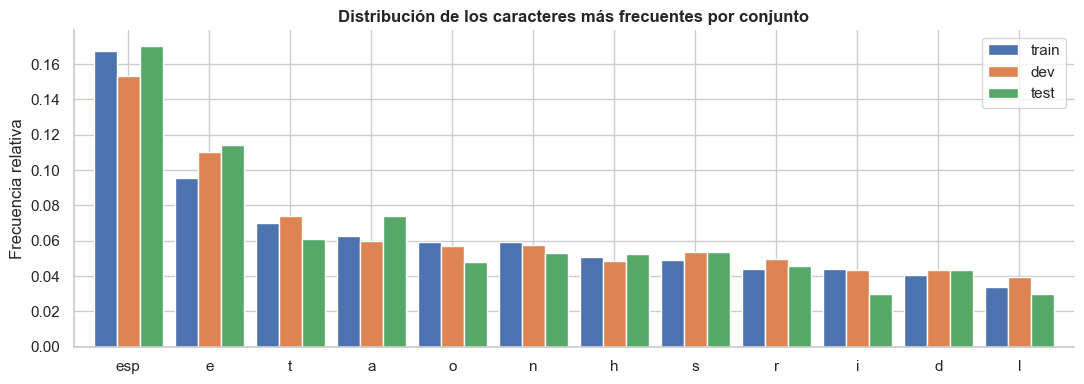

In [19]:
def dist(parrafos):
    """Devuelve la distribución relativa de caracteres sobre una lista de párrafos."""
    texto = "".join(parrafos)
    if not texto:
        return {}
    conteos = Counter(texto)
    total = sum(conteos.values())
    return {c: n / total for c, n in conteos.items()}

def tv(p, q):
    """Distancia de variación total: 0 = distribuciones idénticas, 1 = disjuntas."""
    claves = set(p) | set(q)
    return 0.5 * sum(abs(p.get(c, 0.0) - q.get(c, 0.0)) for c in claves)

vocab_total = sorted(set(texto))

SEED = 42
PROP = {"train": 0.80, "dev": 0.10, "test": 0.10}
TOLERANCIA = 0.04       

def particionar_por_parrafos(df, prop=PROP, seed=SEED, tolerancia=TOLERANCIA, max_intentos=2000):
    """Asigna cada párrafo a train/dev/test al azar, acumulando caracteres hasta alcanzar la proporción pedida.
    Si el reparto no cae dentro de la tolerancia, se reintenta con la semilla siguiente (no usa ninguna métrica del modelo)."""
    largos = df["texto"].str.len().to_numpy()
    total = largos.sum()
    for intento in range(max_intentos):
        rng = np.random.default_rng(seed + intento)
        asignacion = np.empty(len(df), dtype=object)
        acumulado = 0
        for i in rng.permutation(len(df)):
            if acumulado < prop["train"] * total:
                asignacion[i] = "train"
            elif acumulado < (prop["train"] + prop["dev"]) * total:
                asignacion[i] = "dev"
            else:
                asignacion[i] = "test"
            acumulado += largos[i]
        cumple = all(
            (asignacion == s).sum() >= 2 and abs(largos[asignacion == s].sum() / total - prop[s]) <= tolerancia
            for s in prop
        )
        if cumple:
            return asignacion, seed + intento
    raise RuntimeError("No se encontró una partición dentro de la tolerancia; aumentar TOLERANCIA.")

asignacion, semilla_usada = particionar_por_parrafos(df_datos)
df_split = df_datos.assign(split=asignacion)
SPLITS = ["train", "dev", "test"]
parrafos_raw = {s: df_split.loc[df_split["split"] == s, "texto"].tolist() for s in SPLITS}
vocab_train_raw = set("".join(parrafos_raw["train"]))
print(f"Semilla efectiva de la partición: {semilla_usada}\n")


dist_train = dist(parrafos_raw["train"])
total_raw = sum(len(p) for p in df_datos["texto"])
filas = []
for s in SPLITS:
    chars_s = "".join(parrafos_raw[s])
    fuera = Counter(c for c in chars_s if c not in vocab_train_raw)
    filas.append({
        "split": s,
        "párrafos": len(parrafos_raw[s]),
        "caracteres": len(chars_s),
        "% de caracteres": 100 * len(chars_s) / total_raw,
        "distancia a train": 0.0 if s == "train" else tv(dist(parrafos_raw[s]), dist_train),
        "% fuera del vocab. de train": 100 * sum(fuera.values()) / len(chars_s),
        "caracteres fuera": dict(fuera),
    })
tabla_split = pd.DataFrame(filas).set_index("split")
print(tabla_split.round(3).to_string())

top12 = [c for c, _ in Counter("".join(parrafos_raw["train"])).most_common(12)]
idx = {c: i for i, c in enumerate(vocab_total)}
comparacion = pd.DataFrame(
    {
        s: [dist(parrafos_raw[s]).get(c, 0.0) for c in top12]
        for s in SPLITS
    },
    index=["esp" if c == " " else "\\n" if c == "\n" else c for c in top12],
)
ax = comparacion.plot.bar(figsize=(11, 4), rot=0, width=0.85)
ax.set_ylabel("Frecuencia relativa")
ax.set_title("Distribución de los caracteres más frecuentes por conjunto", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Baseline: Naive Bayes de caracteres (desde cero)


In [ ]:
from collections import Counter, defaultdict

K = 5   # largo del contexto (equivalente a n-1 en un modelo de n-gramas)

def construir_pares(texto, k=K):
    """Devuelve (contextos, siguientes_caracteres) para todo el texto."""
    contextos, siguientes = [], []
    for i in range(k, len(texto)):
        contextos.append(texto[i - k:i])
        siguientes.append(texto[i])
    return contextos, siguientes

pares = {s: ([], []) for s in SPLITS}
for s in SPLITS:
    for p in parrafos_raw[s]:
        ctx, sig = construir_pares(p, K)
        pares[s][0].extend(ctx)
        pares[s][1].extend(sig)

X_train_ctx, y_train = pares["train"]
X_dev_ctx,   y_dev   = pares["dev"]
X_test_ctx,  y_test  = pares["test"]

print(f"Contexto: {K} caracteres  |  Clases: {len(vocab_total)} (una por carácter)")
print(f"Pares train: {len(X_train_ctx):,} | dev: {len(X_dev_ctx):,} | test: {len(X_test_ctx):,}")

class NaiveBayesCaracteres:
    def __init__(self, alpha=1.0, usar_contexto=True):
        self.alpha = alpha
        self.usar_contexto = usar_contexto
        self.clases = []
        self.log_priors = {}
        self.log_likelihoods = {}   
        self.vocab = set()

    def fit(self, contextos, siguientes):
        N = len(siguientes)
        conteos_clase = Counter(siguientes)
        conteos_ctx_por_clase = defaultdict(lambda: defaultdict(int))

        #  Vocabulario = unión de caracteres vistos en contexto y en target
        for ctx, sig in zip(contextos, siguientes):
            self.vocab.update(ctx)
            self.vocab.update([sig])
            for ch in ctx:
                conteos_ctx_por_clase[sig][ch] += 1

        V = len(self.vocab)
        self.clases = list(conteos_clase.keys())

        #  log-prior y log-likelihood con suavizado de Laplace
        for c in self.clases:
            self.log_priors[c] = np.log(conteos_clase[c] / N)
            total_ctx = sum(conteos_ctx_por_clase[c].values())
            denom = total_ctx + self.alpha * V
            self.log_likelihoods[c] = {
                ch: np.log((conteos_ctx_por_clase[c][ch] + self.alpha) / denom)
                for ch in self.vocab
            }
            # Carácter de contexto nunca visto: cae al piso de Laplace
            self.log_likelihoods[c]["__OOV__"] = np.log(self.alpha / denom)
        return self

    def _score(self, ctx, clase):
        s = self.log_priors[clase]
        if self.usar_contexto:
            for ch in ctx:
                s += self.log_likelihoods[clase].get(ch, self.log_likelihoods[clase]["__OOV__"])
        return s

    def predict(self, contextos):
        return [max(self.clases, key=lambda c: self._score(ctx, c)) for ctx in contextos]

    def predict_proba(self, ctx):
        """Distribución softmax (numéricamente estable) sobre log-scores."""
        scores = {c: self._score(ctx, c) for c in self.clases}
        m = max(scores.values())
        exp = {c: np.exp(s - m) for c, s in scores.items()}
        Z = sum(exp.values())
        return {c: v / Z for c, v in exp.items()}


#  Baseline 1: solo prior (sin contexto) — el "modelo tonto" 
nb_prior = NaiveBayesCaracteres(alpha=1.0, usar_contexto=False).fit(X_train_ctx, y_train)
#  Baseline 2: Naive Bayes completo con contexto de K caracteres 
nb_ctx   = NaiveBayesCaracteres(alpha=1.0, usar_contexto=True ).fit(X_train_ctx, y_train)

print(f"Baseline 'prior':        {len(nb_prior.clases)} clases, {len(nb_prior.vocab)} caracteres en vocab")
print(f"Baseline 'contexto K={K}': {len(nb_ctx.clases)} clases, {len(nb_ctx.vocab)} caracteres en vocab")

Contexto: 5 caracteres  |  Clases: 67 (una por carácter)
Pares train: 16,154 | dev: 2,728 | test: 1,233
Baseline 'prior':        66 clases, 66 caracteres en vocab
Baseline 'contexto K=5': 66 clases, 66 caracteres en vocab


In [ ]:
# Evaluación del baseline en el conjunto de DEV 
from sklearn.metrics import accuracy_score, top_k_accuracy_score

def evaluar(modelo, X, y, nombre):
    preds = modelo.predict(X)
    acc = accuracy_score(y, preds)

    logps = [-np.log(max(modelo.predict_proba(ctx)[yc], 1e-12))
             for ctx, yc in zip(X, y)]
    ppl = float(np.exp(np.mean(logps)))

    # ¿el carácter correcto está entre los 5 más probables?
    clases = modelo.clases
    probs = np.array([[modelo.predict_proba(ctx).get(c, 0.0) for c in clases] for ctx in X])
    idx_correcto = np.array([clases.index(yc) for yc in y])
    top5 = float(np.mean([idx_correcto[i] in np.argsort(probs[i])[-5:] for i in range(len(y))]))

    print(f"{nombre:<28} acc = {acc:.4f}   perplejidad = {ppl:8.3f}   top-5 = {top5:.4f}")
    return {"modelo": nombre, "accuracy": acc, "perplejidad": ppl, "top5": top5}

filas = []
# Evita KeyError si el dev/test contiene caracteres no vistos en train
def evaluar(modelo, X, y, nombre):
    preds = modelo.predict(X)
    acc = accuracy_score(y, preds)

    
    logps = []
    for ctx, yc in zip(X, y):
        prob = modelo.predict_proba(ctx).get(yc, 0.0)
        logps.append(-np.log(max(prob, 1e-12)))
    ppl = float(np.exp(np.mean(logps)))

    clases = modelo.clases
    probs = np.array([
        [modelo.predict_proba(ctx).get(c, 0.0) for c in clases]
        for ctx in X
    ])
    idx_correcto = np.array([clases.index(yc) if yc in clases else -1 for yc in y])
    top5 = float(np.mean([
        (idx_correcto[i] != -1) and (idx_correcto[i] in np.argsort(probs[i])[-5:])
        for i in range(len(y))
    ]))

    print(f"{nombre:<28} acc = {acc:.4f}   perplejidad = {ppl:8.3f}   top-5 = {top5:.4f}")
    return {"modelo": nombre, "accuracy": acc, "perplejidad": ppl, "top5": top5}

filas.append(evaluar(nb_prior, X_dev_ctx, y_dev, "NB prior (sin contexto)"))
filas.append(evaluar(nb_ctx,   X_dev_ctx, y_dev, f"NB contexto K={K}"))
tabla_baseline = pd.DataFrame(filas).set_index("modelo")
print()
display(tabla_baseline.round(4))

NB prior (sin contexto)      acc = 0.1529   perplejidad =   21.052   top-5 = 0.4542
NB contexto K=5              acc = 0.1829   perplejidad =   18.177   top-5 = 0.5557



,accuracy,perplejidad,top5
modelo,,,
NB prior (sin contexto),0.1529,21.0519,0.4542
NB contexto K=5,0.1829,18.1774,0.5557
